# Detect why there is a pnemonia 

Script for detecte bright or not in a image.

In [31]:
import os
from PIL import Image
import numpy as np

def find_mean_brightness(folder_path):
    brightness_values = []
    std_values = []

    for root, _, filenames in os.walk(folder_path):
        for filename in filenames:
            if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
                continue

            image_path = os.path.join(root, filename)
            with Image.open(image_path) as image:
                img_l = image.convert("L")
                pixels_array = np.array(img_l, dtype=np.float32)

                image_std = float(np.std(pixels_array))
                std_values.append(image_std)

                image_mean_brightness = float(np.mean(pixels_array))
                brightness_values.append(image_mean_brightness)

    if not brightness_values:
        return 0.0, 0.0, 0.0, 0

    mean_brightness = float(np.mean(brightness_values))
    mean_brightness_percent = (mean_brightness / 255.0) * 100.0
    mean_std = float(np.mean(std_values))
    return mean_brightness, mean_brightness_percent, mean_std, len(brightness_values)

In [32]:
def __main__():
    print("Check normal patient")
    dataset_folder_normal_patient = os.path.abspath("../output/chest_xray/test/NORMAL")
    print(f"Calculating mean brightness from: {dataset_folder_normal_patient}")
    normal_mean, normal_percent, normal_std, normal_count = find_mean_brightness(dataset_folder_normal_patient)

    print("Check pneumonia patient")
    dataset_folder_pneumonia_patient = os.path.abspath("../output/chest_xray/test/PNEUMONIA")
    print(f"Calculating mean brightness from: {dataset_folder_pneumonia_patient}")
    pneumonia_mean, pneumonia_percent, pneumonia_std, pneumonia_count = find_mean_brightness(dataset_folder_pneumonia_patient)

    print(f"Normal images: {normal_count}")
    print(f"Pneumonia images: {pneumonia_count}")
    print(f"Mean brightness normal patient: {normal_mean:.2f}/255 ({normal_percent:.2f}%)")
    print(f"Mean brightness pneumonia patient: {pneumonia_mean:.2f}/255 ({pneumonia_percent:.2f}%)")
    print(f"Mean std normal patient: {normal_std:.2f}")
    print(f"Mean std pneumonia patient: {pneumonia_std:.2f}")

__main__()

Check normal patient
Calculating mean brightness from: e:\Dev\CVRIE\output\chest_xray\test\NORMAL
Check pneumonia patient
Calculating mean brightness from: e:\Dev\CVRIE\output\chest_xray\test\PNEUMONIA
Normal images: 234
Pneumonia images: 390
Mean brightness normal patient: 124.10/255 (48.66%)
Mean brightness pneumonia patient: 119.24/255 (46.76%)
Mean std normal patient: 59.92
Mean std pneumonia patient: 55.71


HeatMap des zones avec le plus gros impacts

In [33]:
import matplotlib as plt

def generate_heatmap(folder_path):
    grid_size = 32
    target_size = 256
    step = target_size // grid_size
    
    combined_heatmap = np.zeros((grid_size, grid_size), dtype=np.float32)
    count = 0
    print(f"Grid size: {grid_size}x{grid_size}, Step: {step}")
    for root, _, filenames in os.walk(folder_path):
        for filename in filenames:
            if filename.endswith((".png", ".jpg", ".jpeg")):
                image_path = os.path.join(root, filename)
                with Image.open(image_path) as image:
                    img_l = image.convert("L")
                    pixels_array = np.array(img_l, dtype=np.float32)
                    current_heatmap = np.zeros((grid_size, grid_size))
            for i in range (grid_size):
                for j in range(grid_size):
                    block = pixels_array[i*step:(i+1)*step, j*step:(j+1)*step]
                    current_heatmap[i,j] = np.mean(block)
            combined_heatmap += current_heatmap
            count += 1
    average_heatmap = combined_heatmap / count
    
    return average_heatmap


Ici le Graphique que nous avons en output définis ceci:

La signature normal dans ce cas présent montre l'image beaucoup plus net car il n'y pas d'inflation ni de liquide ce qui veux dire que c'est remplis d'air et donc noir sur les radios, signe d'une bonne santé.
La signature d'un malade elle possède beaucoup plus de "blanc" dans le sens ou plus l'image possède de "blanc" plus il y a du flou dans cette image plus il y a un risque d'inflamation et donc de liquide ce qui rend l'image pas net.

La troisième image permet de voir ou se trouve les poumons et donc voir un concentré de blanc, signe souvent de la ou l'infection se développe.
Rouge = personne malade
Bleu = personne en bonne santé

Generating heatmaps for normal patient
Grid size: 32x32, Step: 8
Generating heatmaps for pneumonia patient
Grid size: 32x32, Step: 8


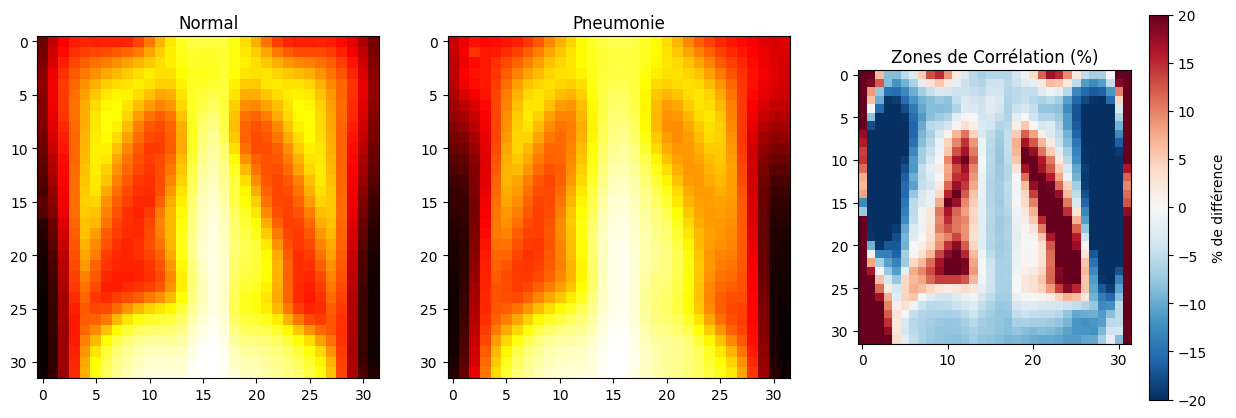

In [34]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def main():
    path_normal_patient = os.path.abspath("../output/chest_xray/test/NORMAL")
    path_pneumonia_patient = os.path.abspath("../output/chest_xray/test/PNEUMONIA")
    
    
    print("Generating heatmaps for normal patient")
    avg_heat_normal = generate_heatmap(path_normal_patient)

    print("Generating heatmaps for pneumonia patient")
    avg_heat_pneumonia = generate_heatmap(path_pneumonia_patient)
    
    if avg_heat_normal is not None and avg_heat_pneumonia is not None:
        diff = ((avg_heat_pneumonia - avg_heat_normal) / avg_heat_normal) * 100
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(avg_heat_normal, cmap='hot')
        plt.title("Normal")

        plt.subplot(1, 3, 2)
        plt.imshow(avg_heat_pneumonia, cmap='hot')
        plt.title("Pneumonie")

        plt.subplot(1, 3, 3)
        plt.imshow(diff, cmap='RdBu_r', vmin=-20, vmax=20)
        plt.colorbar(label='% de différence')
        plt.title("Zones de Corrélation (%)")

        plt.show()
        
if __name__ == "__main__":
    main()

Test via un RandomForestClassifier sur le fichier de train

Loading images from ../output/chest_xray/train/NORMAL...
Loading images from ../output/chest_xray/train/PNEUMONIA...
Successfully loaded 1341 normal images and 3875 pneumonia images.
Train set: 4172 samples, Test set: 1044 samples
Training model...
Model trained successfully.
Evaluating model...

--- Evaluation Results ---
Accuracy: 0.8755
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.85      0.79       287
           1       0.94      0.89      0.91       757

    accuracy                           0.88      1044
   macro avg       0.84      0.87      0.85      1044
weighted avg       0.88      0.88      0.88      1044

ROC AUC: 0.9503
R2 Score (on probabilities): 0.5819
Confusion Matrix:
 [[243  44]
 [ 86 671]]
Generating plot...


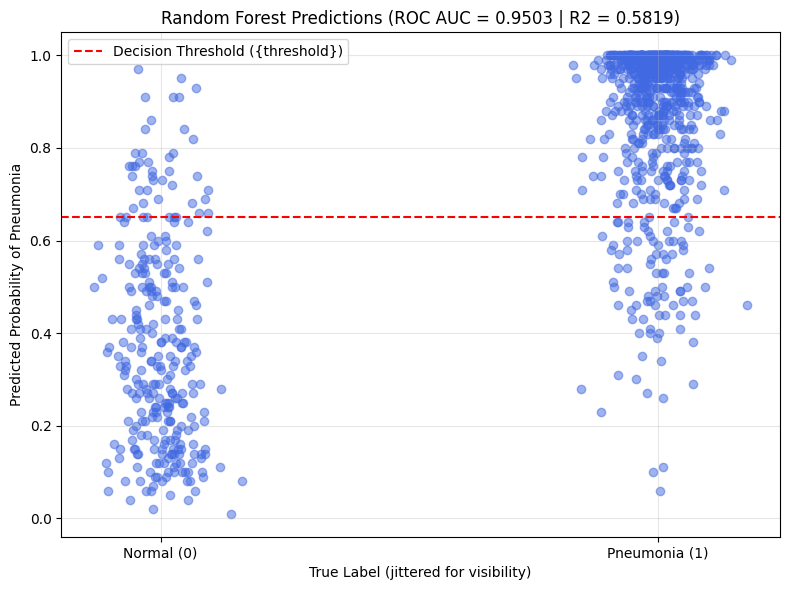

In [ ]:
import numpy as np
import os
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix, r2_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def get_center_image(arr, npix):
    center = [shape // 2 for shape in arr.shape]
    slices = tuple(slice(max(0, c - npix), c + npix) for c in center)
    return arr[slices]

def load_images_from_folder(folder, label, npix=50):
    images = []
    labels = []
    
    if not os.path.exists(folder):
        print(f"ERROR: Directory not found -> {os.path.abspath(folder)}")
        return images, labels

    print(f"Loading images from {folder}...")
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            try:
                img = Image.open(path).convert('L')
                arr = np.array(img)
                
                arr_centered = get_center_image(arr, npix)
                
                images.append(arr_centered.flatten())
                labels.append(label)
            except Exception as e:
                print(f"Skipped {path}: {e}")
                
    return images, labels

path_normal = "../output/chest_xray/train/NORMAL"
path_pneu = "../output/chest_xray/train/PNEUMONIA"

train_normal_x, train_normal_y = load_images_from_folder(path_normal, 0)
train_pneu_x, train_pneu_y = load_images_from_folder(path_pneu, 1)

print(f"Successfully loaded {len(train_normal_x)} normal images and {len(train_pneu_x)} pneumonia images.")

if len(train_normal_x) == 0 or len(train_pneu_x) == 0:
    raise ValueError("directory is empty or not found. Please check your paths.")

X = np.array(train_normal_x + train_pneu_x)
y = np.array(train_normal_y + train_pneu_y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)
print(f"Train set: {len(X_train)} samples, Test set: {len(X_test)} samples")

model = RandomForestClassifier(n_estimators=100, random_state=42)
print("Training model...")
model.fit(X_train, y_train)
print("Model trained successfully.")

print("Evaluating model...")
y_proba = model.predict_proba(X_test)[:, 1]
threshold = 0.65
y_pred_strict = (y_proba >= threshold)

print("\nRESULTS\n")
print(f"Accuracy: {accuracy_score(y_test, y_pred_strict):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred_strict))

if y_proba is not None:
    roc_auc = roc_auc_score(y_test, y_proba)
    r2 = r2_score(y_test, y_proba) 
    print(f"ROC AUC: {roc_auc:.4f}")
    print(f"R2 Score (on probabilities): {r2:.4f}")
else:
    print("Probabilities unavailable for ROC AUC and R2.")
        
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_strict))

if y_proba is not None:
    print("Generating plot...")
    plt.figure(figsize=(8, 6))
    
    jitter = np.random.normal(0, 0.05, size=len(y_test))
    plt.scatter(y_test + jitter, y_proba, alpha=0.5, color='royalblue')
    
    plt.axhline(threshold, color='red', linestyle='--', label='Decision Threshold ({threshold})')
    
    plt.xlabel('True Label (jittered for visibility)')
    plt.ylabel('Predicted Probability of Pneumonia')
    plt.title(f'Random Forest Predictions (ROC AUC = {roc_auc:.4f} | R2 = {r2:.4f})')
    plt.xticks([0, 1], ['Normal (0)', 'Pneumonia (1)'])
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

Test via un RandomForestClassifier sur le fichier de test

Loading images from ../output/chest_xray/test/NORMAL...
Loading images from ../output/chest_xray/test/PNEUMONIA...
Successfully loaded 234 normal images and 390 pneumonia images.
Train set: 499 samples, Test set: 125 samples
Training model...
Model trained successfully.
Evaluating model...

--- Evaluation Results ---
Accuracy: 0.8000
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.73      0.75        52
           1       0.82      0.85      0.83        73

    accuracy                           0.80       125
   macro avg       0.80      0.79      0.79       125
weighted avg       0.80      0.80      0.80       125

ROC AUC: 0.8733
R2 Score (on probabilities): 0.4169
Confusion Matrix:
 [[38 14]
 [11 62]]
Generating plot...


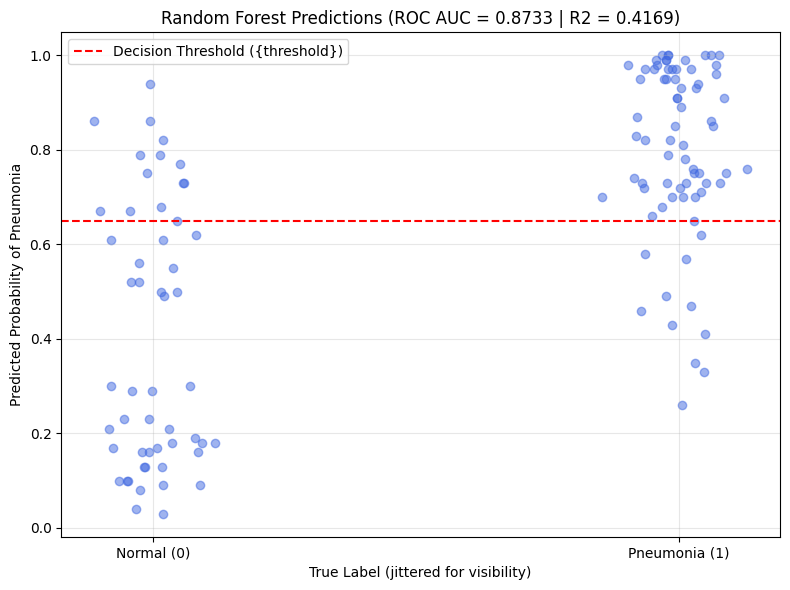

In [ ]:
import numpy as np
import os
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix, r2_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def get_center_image(arr, npix):
    center = [shape // 2 for shape in arr.shape]
    slices = tuple(slice(max(0, c - npix), c + npix) for c in center)
    return arr[slices]

def load_images_from_folder(folder, label, npix=50):
    images = []
    labels = []
    
    if not os.path.exists(folder):
        print(f"Directory not found")
        return images, labels

    print(f"Loading images from {folder}...")
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            try:
                img = Image.open(path).convert('L')
                arr = np.array(img)
                
                arr_centered = get_center_image(arr, npix)
                
                images.append(arr_centered.flatten())
                labels.append(label)
            except Exception as e:
                print(f"Skipped {path}: {e}")
                
    return images, labels

path_normal = "../output/chest_xray/test/NORMAL"
path_pneu = "../output/chest_xray/test/PNEUMONIA"

train_normal_x, train_normal_y = load_images_from_folder(path_normal, 0)
train_pneu_x, train_pneu_y = load_images_from_folder(path_pneu, 1)

print(f"Successfully loaded {len(train_normal_x)} normal images and {len(train_pneu_x)} pneumonia images.")

if len(train_normal_x) == 0 or len(train_pneu_x) == 0:
    raise ValueError("directory is empty or not found. Please check your paths.")

X = np.array(train_normal_x + train_pneu_x)
y = np.array(train_normal_y + train_pneu_y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)
print(f"Train set: {len(X_train)} samples, Test set: {len(X_test)} samples")

model = RandomForestClassifier(n_estimators=100, random_state=42)
print("Training model...")
model.fit(X_train, y_train)
print("Model trained successfully.")

print("Evaluating model...")
y_proba = model.predict_proba(X_test)[:, 1]
threshold = 0.65
y_pred_strict = (y_proba >= threshold)

print("\nRESULTS\n")
print(f"Accuracy: {accuracy_score(y_test, y_pred_strict):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred_strict))

if y_proba is not None:
    roc_auc = roc_auc_score(y_test, y_proba)
    r2 = r2_score(y_test, y_proba) 
    print(f"ROC AUC: {roc_auc:.4f}")
    print(f"R2 Score (on probabilities): {r2:.4f}")
else:
    print("Probabilities unavailable for ROC AUC and R2.")
        
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_strict))

if y_proba is not None:
    print("Generating plot...")
    plt.figure(figsize=(8, 6))
    
    jitter = np.random.normal(0, 0.05, size=len(y_test))
    plt.scatter(y_test + jitter, y_proba, alpha=0.5, color='royalblue')
    
    plt.axhline(threshold, color='red', linestyle='--', label='Decision Threshold ({threshold})')
    
    plt.xlabel('True Label (jittered for visibility)')
    plt.ylabel('Predicted Probability of Pneumonia')
    plt.title(f'Random Forest Predictions (ROC AUC = {roc_auc:.4f} | R2 = {r2:.4f})')
    plt.xticks([0, 1], ['Normal (0)', 'Pneumonia (1)'])
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

IA qui s'entraine via le fichier de **TRAIN** pour ensuite vérifié les fichiers de **TEST** 

Loading images from ../output/chest_xray/train/NORMAL...
Loading images from ../output/chest_xray/train/PNEUMONIA...

Train set loaded: 5216 samples.
Loading images from ../output/chest_xray/test/NORMAL...
Loading images from ../output/chest_xray/test/PNEUMONIA...
Test set loaded: 624 samples.

Training model on the FULL train set...
Model trained successfully.

Evaluating model on the UNSEEN test set...

--- Evaluation Results ---
Accuracy: 0.8093
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.71      0.73       234
           1       0.83      0.87      0.85       390

    accuracy                           0.81       624
   macro avg       0.80      0.79      0.79       624
weighted avg       0.81      0.81      0.81       624

ROC AUC: 0.8790
R2 Score (on probabilities): 0.3927
Confusion Matrix:
 [[165  69]
 [ 50 340]]
Generating plot...


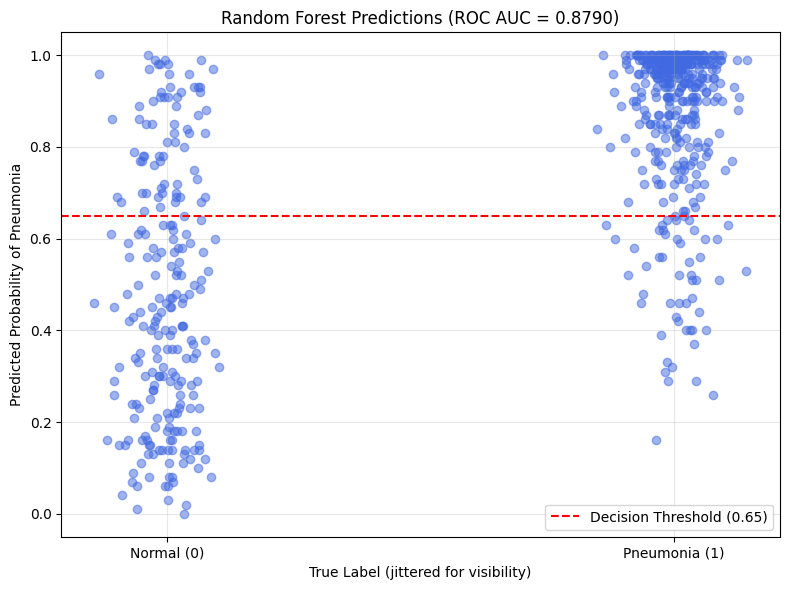

In [ ]:
import numpy as np
import os
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix, r2_score
import matplotlib.pyplot as plt

def get_center_image(arr, npix):
    center = [shape // 2 for shape in arr.shape]
    slices = tuple(slice(max(0, c - npix), c + npix) for c in center)
    return arr[slices]

def load_images_from_folder(folder, label, npix=50):
    images = []
    labels = []
    
    if not os.path.exists(folder):
        print(f"Directory not found")
        return images, labels

    print(f"Loading images from {folder}...")
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        if path.lower().endswith(('.png', '.jpg', '.jpeg')):
            try:
                img = Image.open(path).convert('L')
                arr = np.array(img)
                
                arr_centered = get_center_image(arr, npix)
                
                images.append(arr_centered.flatten())
                labels.append(label)
            except Exception as e:
                print(f"Skipped {path}: {e}")
                
    return images, labels

train_normal_dir = "../output/chest_xray/train/NORMAL"
train_pneu_dir = "../output/chest_xray/train/PNEUMONIA"

test_normal_dir = "../output/chest_xray/test/NORMAL"
test_pneu_dir = "../output/chest_xray/test/PNEUMONIA"

train_normal_x, train_normal_y = load_images_from_folder(train_normal_dir, 0)
train_pneu_x, train_pneu_y = load_images_from_folder(train_pneu_dir, 1)

if len(train_normal_x) == 0 or len(train_pneu_x) == 0:
    raise ValueError("Train directories are empty or not found.")

X_train = np.array(train_normal_x + train_pneu_x)
y_train = np.array(train_normal_y + train_pneu_y)
print(f"\nTrain set loaded: {len(X_train)} samples.")

test_normal_x, test_normal_y = load_images_from_folder(test_normal_dir, 0)
test_pneu_x, test_pneu_y = load_images_from_folder(test_pneu_dir, 1)

if len(test_normal_x) == 0 or len(test_pneu_x) == 0:
    raise ValueError("Test directories are empty or not found.")

X_test = np.array(test_normal_x + test_pneu_x)
y_test = np.array(test_normal_y + test_pneu_y)
print(f"Test set loaded: {len(X_test)} samples.\n")

model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
print("Training model on the FULL train set...")
model.fit(X_train, y_train)
print("Model trained successfully.\n")

print("Evaluating model on the test set...")
y_proba = model.predict_proba(X_test)[:, 1]

threshold = 0.65
y_pred_strict = (y_proba >= threshold).astype(int)

print("\nRESULTS\n")
print(f"Accuracy: {accuracy_score(y_test, y_pred_strict):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred_strict))

if y_proba is not None:
    roc_auc = roc_auc_score(y_test, y_proba)
    r2 = r2_score(y_test, y_proba) 
    print(f"ROC AUC: {roc_auc:.4f}")
    print(f"R2 Score (on probabilities): {r2:.4f}")
        
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_strict))

if y_proba is not None:
    print("Generating plot...")
    plt.figure(figsize=(8, 6))
    
    jitter = np.random.normal(0, 0.05, size=len(y_test))
    plt.scatter(y_test + jitter, y_proba, alpha=0.5, color='royalblue')
    
    plt.axhline(threshold, color='red', linestyle='--', label=f'Decision Threshold ({threshold})')
    
    plt.xlabel('True Label (jittered for visibility)')
    plt.ylabel('Predicted Probability of Pneumonia')
    plt.title(f'Random Forest Predictions (ROC AUC = {roc_auc:.4f})')
    plt.xticks([0, 1], ['Normal (0)', 'Pneumonia (1)'])
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

PROBABLEMENT FAUX, A SUPP

LinearRegression MSE: 0.1605
LinearRegression R2: 0.1946
Accuracy (threshold 0.5): 0.7423
Confusion matrix:
 [[ 56 231]
 [ 38 719]]


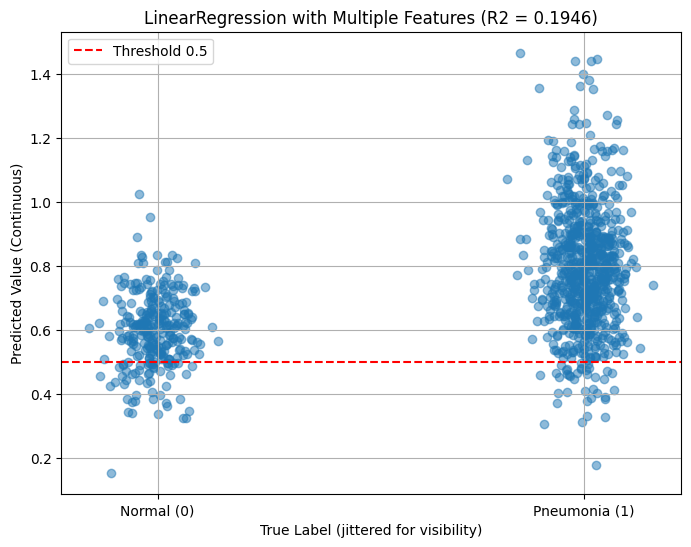

In [38]:
import numpy as np
from PIL import Image
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

normal_dir = os.path.abspath("../output/chest_xray/train/NORMAL")
pneu_dir = os.path.abspath("../output/chest_xray/train/PNEUMONIA")

def load_multi_features(normal_dir, pneu_dir):
    X = []
    y = []
    for dir_path, label in ((normal_dir, 0), (pneu_dir, 1)):
        if not os.path.exists(dir_path):
            print(f"Dir not found: {dir_path}")
            continue
        for root, _, files in os.walk(dir_path):
            for fname in files:
                if not fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                    continue
                path = os.path.join(root, fname)
                try:
                    with Image.open(path) as img:
                        arr = np.array(img.convert('L'), dtype=np.float32)
                except Exception as e:
                    print(f"Skipped {path}: {e}")
                    continue
                mean_val = float(np.mean(arr))
                std_val = float(np.std(arr))
                min_val = float(np.min(arr))
                max_val = float(np.max(arr))
                median_val = float(np.median(arr))
                X.append([mean_val, std_val, min_val, max_val, median_val])
                y.append(label)
    if not X:
        raise ValueError("No images found in provided folders")
    return np.array(X), np.array(y)

X, y = load_multi_features(normal_dir, pneu_dir)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"LinearRegression MSE: {mse:.4f}")
print(f"LinearRegression R2: {r2:.4f}")

y_pred_class = (y_pred >= 0.5).astype(int)
acc = accuracy_score(y_test, y_pred_class)
print(f"Accuracy (threshold 0.5): {acc:.4f}")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_class))

plt.figure(figsize=(8,6))
plt.scatter(y_test + np.random.normal(0, 0.05, size=len(y_test)), y_pred, alpha=0.5)
plt.axhline(0.5, color='r', linestyle='--', label='Threshold 0.5')
plt.xlabel('True Label (jittered for visibility)')
plt.ylabel('Predicted Value (Continuous)')
plt.title(f'LinearRegression with Multiple Features (R2 = {r2:.4f})')
plt.xticks([0, 1], ['Normal (0)', 'Pneumonia (1)'])
plt.legend()
plt.grid(True)
plt.show()

PROBABLEMENT FAUX, A SUPP